In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

df = pd.read_csv("../data/contributions.csv", dtype=str)
indiv_df = pd.read_csv("../contributions_individuals.csv", dtype=str)

In [15]:
print(len(df))
print(len(indiv_df))

159173
158838


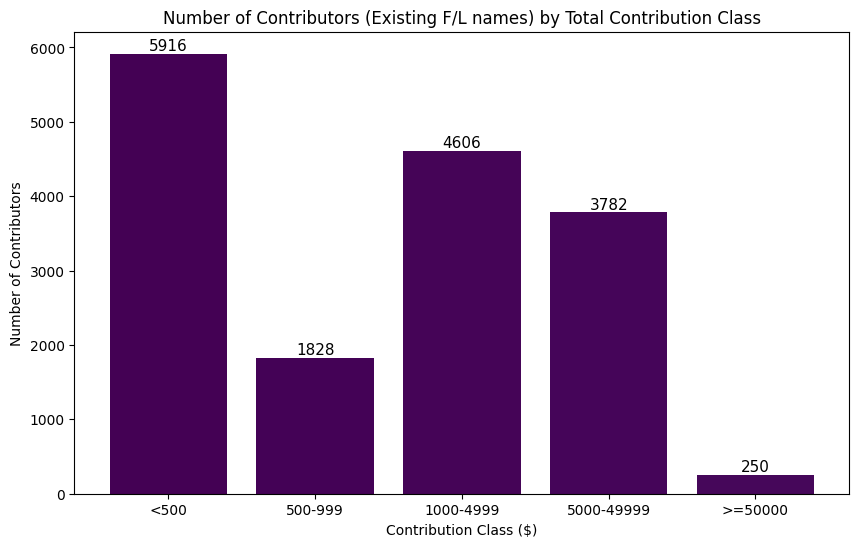

In [ ]:
indiv_df['contribution_receipt_amount'] = pd.to_numeric(indiv_df['contribution_receipt_amount'], errors='coerce')

# Aggregate contributions per contributor
total_per_contributor = indiv_df.groupby('contributor_name')['contribution_receipt_amount'].sum().reset_index()

# Classification function
def classify_contribution(amount):
    if amount < 500:
        return '<500'
    elif 500 <= amount < 1000:
        return '500-999'
    elif 1000 <= amount < 5000:
        return '1000-4999'
    elif 5000 <= amount < 50000:
        return '5000-49999'
    else:
        return '>=50000'

total_per_contributor['class'] = total_per_contributor['contribution_receipt_amount'].apply(classify_contribution)

# Define custom category 
class_order = ['<500', '500-999', '1000-4999', '5000-49999', '>=50000']
total_per_contributor['class'] = pd.Categorical(total_per_contributor['class'], categories=class_order, ordered=True)

# Count contributors per class
class_counts = total_per_contributor['class'].value_counts().sort_index()

# Plot
plt.figure(figsize=(10,6))
bars = plt.bar(class_counts.index, class_counts.values, color=plt.cm.viridis(range(len(class_counts))))

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom', fontsize=11)

plt.xlabel("Contribution Class ($)")
plt.ylabel("Number of Contributors")
plt.title("Number of Contributors (Existing F/L names) by Total Contribution Class")
plt.show()
